<a href="https://colab.research.google.com/github/leoncionsuen12-arch/Heart-Disease-Prediction-UCI-Cleveland-/blob/main/notebooks/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Prediction (UCI Cleveland)

**Course:** SE309 – AI and Data Science for Innovation in Health Science  
**Topic code:** SE309-02  
**Working as:** Individual  
**Full name:** LEONCIO NSUE NKILI ASANGONO
**Student number:** 220201902  
**GitHub username:** leoncionsuen12-arch  
**Repository:** https://github.com/leoncionsuen12-arch/Heart-Disease-Prediction-UCI-Cleveland-$0

## 1. Problem

This project uses the UCI Cleveland dataset to study how well two machine learning models can identify records with and without heart disease. It compares logistic regression and a decision tree with a baseline that always predicts the most common class in the training data. All three models are evaluated on the same test set using sensitivity and specificity. Sensitivity measures how often a model correctly identifies cases with heart disease, while specificity measures how often it correctly identifies cases without it. The results are intended for an academic comparison of the models.

## 2. Data

This project uses the processed Cleveland file from the [UCI Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease). It contains 303 records, 13 input variables and one target variable called `num`. UCI lists the dataset under the Creative Commons Attribution 4.0 license. The notebook loads the file directly from the UCI repository.

### Data note

1. **Who is included?** The records come from patients in the Cleveland cohort. People who were never evaluated or enrolled in that cohort are outside the dataset.
2. **Why were the data collected?** The associated study evaluated a method for identifying coronary artery disease.
3. **When and where?** This project uses the Cleveland cohort from the United States. The associated paper was published in 1989. The UCI dataset overview does not specify the exact collection years.
4. **What is the label?** UCI uses `num = 0` for absence of heart disease and `num = 1–4` for presence. This project combines values `1–4` into one positive class. The UCI documentation describes an angiographic criterion and does not name the individual label assessors.
5. **What is missing?** Four values are missing in `ca` and two in `thal`. UCI marks these entries with `?`. The missingness mechanism cannot be determined from the file alone.
6. **Which values are impossible?** Zero or negative values for age, resting blood pressure, serum cholesterol and maximum heart rate are flagged for review. Zero is valid for some other variables, including `ca`, where it means zero major vessels recorded as colored by fluoroscopy.
7. **When are the inputs available?** Age and sex can be recorded early, while other measurements require laboratory tests or an exercise test. The models exclude `ca` and `thal` because they require additional testing.
8. **What is known about consent?** UCI reports that names and Social Security numbers were removed or replaced. The dataset overview does not describe the original consent terms.

## 3. Setup

In [ ]:
import pandas as pd

SEED = 42
DATA_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(DATA_URL, header=None, names=columns, na_values="?")

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
display(df.head())

Rows: 303 | Columns: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 4. Exploration

This section checks the target distribution, missing values, and the ranges of selected numerical variables before training the models.

In [ ]:
disease_status = df["num"].gt(0).map({
    False: "No heart disease",
    True: "Heart disease"
})

print("Records by disease status")
display(disease_status.value_counts().to_frame("Records"))

print("Missing values by column")
display(df.isna().sum().to_frame("Missing values"))

numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]

print("Five-number summary")
display(
    df[numeric_columns].describe()
    .loc[["min", "25%", "50%", "75%", "max"]]
)

print("Zero or negative values in measurements expected to be positive")
positive_columns = ["age", "trestbps", "chol", "thalach"]
display(df[positive_columns].le(0).sum().to_frame("Values to check"))

Records by disease status


,Records
num,
No heart disease,164
Heart disease,139


Missing values by column


,Missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Five-number summary


,age,trestbps,chol,thalach,oldpeak
min,29.0,94.0,126.0,71.0,0.0
25%,48.0,120.0,211.0,133.5,0.0
50%,56.0,130.0,241.0,153.0,0.8
75%,61.0,140.0,275.0,166.0,1.6
max,77.0,200.0,564.0,202.0,6.2


Zero or negative values in measurements expected to be positive


,Values to check
age,0
trestbps,0
chol,0
thalach,0


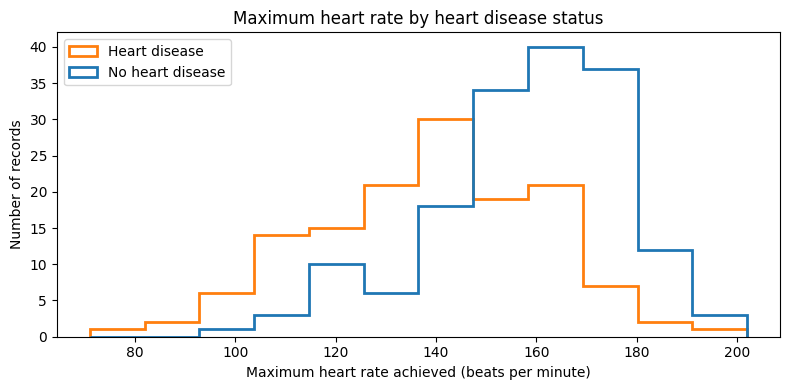

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.hist(
    [
        df.loc[disease_status == "No heart disease", "thalach"],
        df.loc[disease_status == "Heart disease", "thalach"]
    ],
    bins=12,
    histtype="step",
    linewidth=2,
    label=["No heart disease", "Heart disease"]
)

plt.title("Maximum heart rate by heart disease status")
plt.xlabel("Maximum heart rate achieved (beats per minute)")
plt.ylabel("Number of records")
plt.legend()
plt.tight_layout()
plt.show()

The distributions of maximum heart rate overlap between the two groups. This means that similar maximum heart rates occur in records both with and without heart disease, so this measurement alone does not cleanly separate the groups.

## 5. Preparation

The original target `num` is converted into two classes: `0` means no heart disease and `1` means heart disease is present. The input variables exclude `num`, `ca`, and `thal`. The original target `num` contains the answer the models are meant to predict, while `ca` and `thal` require additional tests.

The data are split into a training set (75%) and a test set (25%). Stratification keeps the proportion of the two classes similar in both sets. The models and preprocessing steps will be fitted using the training set. The test set is reserved for evaluation.


In [ ]:
from sklearn.model_selection import train_test_split

y = df["num"].gt(0).astype(int)
X = df.drop(columns=["num", "ca", "thal"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=SEED
)

print(f"Training records: {len(X_train)}")
print(f"Test records: {len(X_test)}")
print(f"Input variables: {X_train.shape[1]}")

Training records: 227
Test records: 76
Input variables: 11


## 6. Methods

This project compares three classifiers:

- **Majority-class baseline:** Always predicts the most common class in the training set. It provides a reference for evaluating the other models.
- **Logistic regression:** Estimates the probability that a record belongs to the heart disease class.
- **Decision tree:** Uses a series of rules to classify each record. Its depth is limited to three to keep the rules easier to interpret.

Numerical features are scaled, and categorical features are converted into binary indicators. Preprocessing and model training use only the training set.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope"]

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree": DecisionTreeClassifier(max_depth=3, random_state=SEED)
}

trained_models = {}

for name, model in models.items():
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ])

    pipeline = make_pipeline(preprocessing, model)
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"Trained: {name}")

Trained: Majority baseline
Trained: Logistic regression
Trained: Decision tree


## 7. Results

All three models are evaluated on the same 76 test records. The table reports accuracy, sensitivity, specificity, and the number of false negatives and false positives for each model.

In [ ]:
from sklearn.metrics import confusion_matrix

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy (%)": 100 * (tp + tn) / len(y_test),
        "Sensitivity (%)": 100 * tp / (tp + fn),
        "Specificity (%)": 100 * tn / (tn + fp),
        "False negatives": fn,
        "False positives": fp
    })

results_table = pd.DataFrame(results).set_index("Model")
display(results_table.round(1))

,Accuracy (%),Sensitivity (%),Specificity (%),False negatives,False positives
Model,,,,,
Majority baseline,53.9,0.0,100.0,35,0
Logistic regression,88.2,88.6,87.8,4,5
Decision tree,78.9,80.0,78.0,7,9


### Interpretation

The test set contained 35 records with heart disease and 41 without it. The majority-class baseline predicted that every record had no heart disease. It achieved 53.9% accuracy and 100% specificity, but its sensitivity was 0% because it missed all 35 cases with heart disease.

Logistic regression performed best on this test split. It achieved 88.2% accuracy, 88.6% sensitivity, and 87.8% specificity. It correctly identified 31 of the 35 cases with heart disease and 36 of the 41 cases without it, producing 4 false negatives and 5 false positives.

The decision tree achieved 78.9% accuracy, 80.0% sensitivity, and 78.0% specificity. It produced 7 false negatives and 9 false positives. Logistic regression made fewer errors of both types on this test set. These results come from a single split of the Cleveland dataset.

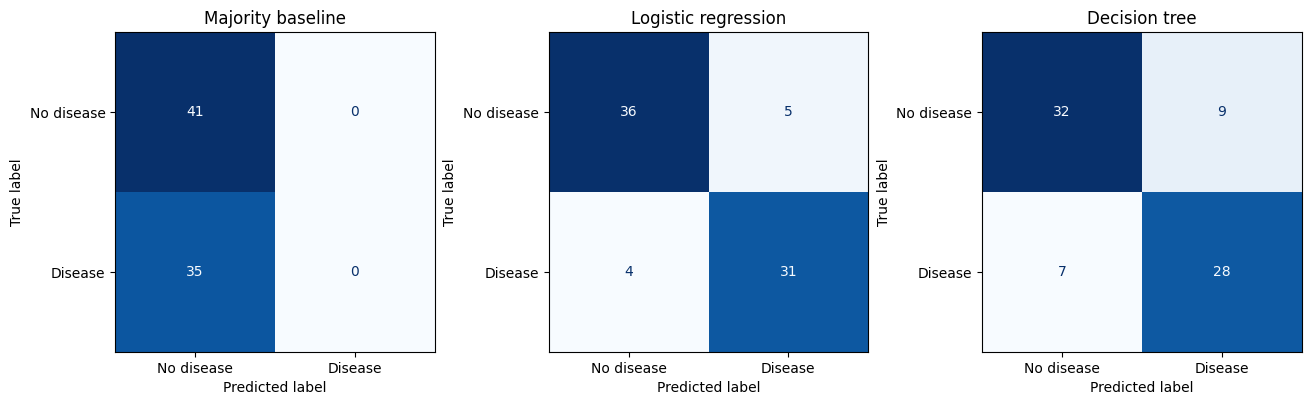

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

for (name, model), ax in zip(trained_models.items(), axes):
    predictions = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["No disease", "Disease"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.show()

### Confusion matrices

Each matrix shows the number of records by actual and predicted class. The bottom-left cell contains false negatives, and the top-right cell contains false positives. Logistic regression has 4 false negatives and 5 false positives, compared with 7 false negatives and 9 false positives for the decision tree.

## 8. Limitations and possible harms

This study uses 303 historical records from a single cohort in Cleveland. The results are based on one test set of 76 records. Performance may differ with another split or with patients from other hospitals. The analysis also combines target values 1–4 into a single positive class, so it evaluates disease presence without distinguishing among those original categories.

If a model like this were used in clinical practice, false negatives could give patients false reassurance and delay further evaluation. False positives could cause anxiety and lead to unnecessary testing. Even the best-performing model in this experiment missed 4 of the 35 cases with heart disease.

This project is an academic comparison. Before any clinical use, the model would need evaluation on independent, more recent data, including an assessment of performance across relevant patient groups.

In [ ]:
from sklearn.inspection import permutation_importance

logistic_model = trained_models["Logistic regression"]

importance = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring="balanced_accuracy",
    n_repeats=30,
    random_state=SEED
)

feature_importance = pd.DataFrame({
    "Variable": X_test.columns,
    "Average drop (percentage points)": 100 * importance.importances_mean
}).sort_values("Average drop (percentage points)", ascending=False)

display(feature_importance.head(5).round(2))

,Variable,Average drop (percentage points)
2,cp,11.96
9,oldpeak,9.81
1,sex,8.51
7,thalach,6.33
3,trestbps,5.90


### Feature importance

Chest pain type (`cp`) had the highest permutation importance for logistic regression on the test set. Shuffling its values reduced balanced accuracy by 11.96 percentage points on average. The next largest decreases were 9.81 points for `oldpeak` (exercise-induced ST depression relative to rest) and 8.51 points for `sex` (recorded sex).

Balanced accuracy is the average of sensitivity and specificity. These results show which variables the model relied on most in this test split. The ranking measures their contribution to prediction. It cannot establish whether a variable causes heart disease.

## 9. Contributions

This was an individual project. I assembled the notebook in Google Colab, ran the code cells, and checked the dataset size, class counts, and model results, and I verified the reported results against the outputs from my Colab notebook.

## 10. External code, libraries and AI tools

| Tool | Used for | Notebook sections |
|---|---|---|
| pandas | Loading the dataset, checking missing values, and presenting results in tables. | 3, 4, 7 |
| Matplotlib | Plotting the heart rate distributions and displaying confusion matrices. | 4, 7 |
| scikit-learn | Splitting the data, preprocessing, training classifiers, calculating metrics, and estimating permutation importance. | 5, 6, 7 |
| ChatGPT | Helped develop and refine the Python code, and interpret the Colab results. | 3–7 |

## 11. References

- Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). [Heart Disease dataset](https://doi.org/10.24432/C52P4X). UCI Machine Learning Repository. This project uses the processed Cleveland file.
- UCI Machine Learning Repository. [Heart Disease variable descriptions](https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/heart-disease.names).
- scikit-learn. [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).